# TP – Analisando Grafos do SNAP · G13 `soc-RedditHyperlinks`

Teoria dos Grafos – IC/UFBA · Prof. Bruno Pereira dos Santos
Matrícula **224216276**

Rede de hiperlinks entre subreddits do Reddit (SNAP, Kumar et al., 2018). Usamos o arquivo
`soc-redditHyperlinks-body.tsv` (links no corpo dos posts).

Os algoritmos e métricas pedidos estão implementados em `src/` e validados contra o networkx.
Para rodar do zero: `python data/raw/download.py` e depois *Kernel → Restart & Run All*.

## 0. Configuração e determinação do grafo

In [1]:
import sys, platform, os, math, random, time, json
from pathlib import Path
import numpy as np, pandas as pd, networkx as nx, igraph as ig
import matplotlib
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd()))
from src import tratamento as T, algoritmos as A, metricas as M, robustez as R

SEED = 224216276
random.seed(SEED); np.random.seed(SEED % 2**32)
RAW = Path("data/raw/soc-redditHyperlinks-body.tsv")
PROC, FIG, RES = Path("data/processed"), Path("figuras"), Path("resultados")
for p in (PROC, FIG, RES): p.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})

def salvar_tabela(df, nome, **kw):
    df.to_csv(RES / f"{nome}.csv", index=kw.get("index", True))
    df.to_latex(RES / f"{nome}.tex", index=kw.get("index", True), float_format="%.4g")
    return df

print("Python", platform.python_version(), "|", platform.platform())
print("CPU:", platform.processor() or platform.machine(), "| núcleos:", os.cpu_count())
print("networkx", nx.__version__, "| igraph", ig.__version__, "| pandas", pd.__version__)

Python 3.13.18 | Linux-6.18.44-fc-v726-x86_64-with-glibc2.39
CPU: x86_64 | núcleos: 2
networkx 3.7 | igraph 1.0.0 | pandas 3.0.5


**Regra de mapeamento:** $f(M) = ((\text{soma dos dígitos de } M) \times (\text{últimos 2 dígitos de } M + 1)) \bmod 129$; se 0, usar 129.

In [2]:
def indice_grafo(M: int) -> int:
    s = sum(int(d) for d in str(M))
    u = M % 100
    r = (s * (u + 1)) % 129
    print(f"soma dos dígitos = {s}; últimos 2 dígitos = {u:02d}")
    print(f"({s} × {u + 1}) mod 129 = {s * (u + 1)} mod 129 = {r}")
    return r or 129

assert indice_grafo(225216327) == 66 and indice_grafo(2025000078) == 90   # exemplos do enunciado
print("---")
G_ID = indice_grafo(224216276)
print(f"→ Grafo G{G_ID}: soc-RedditHyperlinks (Social networks)")

soma dos dígitos = 30; últimos 2 dígitos = 27
(30 × 28) mod 129 = 840 mod 129 = 66
soma dos dígitos = 24; últimos 2 dígitos = 78
(24 × 79) mod 129 = 1896 mod 129 = 90
---
soma dos dígitos = 32; últimos 2 dígitos = 76
(32 × 77) mod 129 = 2464 mod 129 = 13
→ Grafo G13: soc-RedditHyperlinks (Social networks)


> Observação: na planilha ANALISANDO-SNAP-DATASET o mesmo dataset aparece como G13 (Social networks), G72 (Signed), G92 (Temporal) e G109 (Online communities). Usamos a entrada G13.

## 1. Carga e descrição do grafo original

In [3]:
df = T.carregar_bruto(RAW)
desc = pd.Series(T.descrever_bruto(df), name="valor").to_frame()
salvar_tabela(desc, "01_dados_originais")

,valor
posts (linhas),286561
subreddits distintos,35776
pares dirigidos distintos,137821
posts por par (média),2.079
posts por par (máximo),548
links positivos (+1),265491
links negativos (-1),21070
auto-loops,0
início,2013-12-31 16:39:58
fim,2017-04-30 16:58:21


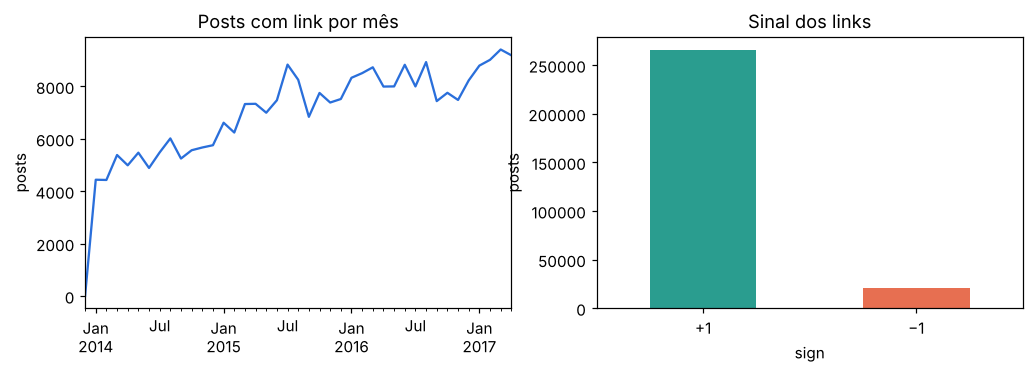

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
df.set_index("ts").resample("ME")["sign"].count().plot(ax=ax[0], color="#2a6fdb")
ax[0].set(title="Posts com link por mês", xlabel="", ylabel="posts")
df["sign"].value_counts().rename({1: "+1", -1: "−1"}).plot.bar(ax=ax[1], color=["#2a9d8f", "#e76f51"], rot=0)
ax[1].set(title="Sinal dos links", ylabel="posts")
fig.savefig(FIG / "01_original_tempo_sinal.png"); plt.show()

A planilha informa 55.863 vértices e 858.490 arestas porque descreve o dataset completo (arquivos *body* + *title*). Aqui usamos apenas o *body*.

## 2. Tratamento dos dados

In [5]:
e_dir = T.arestas_dirigidas(df)
e_und = T.arestas_nao_dirigidas(e_dir)
e_dir.to_csv(PROC / "arestas_dirigidas.csv", index=False)
e_und.to_csv(PROC / "arestas_nao_dirigidas.csv", index=False)

G_dir = T.grafo_dirigido(e_dir)
G_und = T.grafo_nao_dirigido(e_und)
G_lcc = T.maior_componente(G_und)
nx.write_edgelist(G_lcc, PROC / "maior_componente.edgelist.gz", data=["count", "sign", "weight"])

trat = pd.DataFrame([
    ["Temporal → estático", "União de todos os posts de 31/12/2013 a 30/04/2017", f"{len(df):,} posts"],
    ["Remoção de auto-loops", "Verificado: o arquivo não tem auto-loops", f"{(df.src == df.dst).sum()} removidos"],
    ["Multigrafo → simples (dirigido)", "Uma aresta por par (u→v); count = nº de posts; sign = sinal majoritário", f"{len(e_dir):,} arestas"],
    ["Dirigido → não dirigido", "Junta u→v e v→u; count somado; sign pelo saldo ponderado", f"{len(e_und):,} arestas"],
    ["Pesos", "w = 1/count (pares com mais links ficam mais próximos)", "Dijkstra, Bellman-Ford, Floyd-Warshall, AGM"],
    ["Maior componente conexa", "Usada em distâncias, small-world e robustez", f"{G_lcc.number_of_nodes():,} vértices / {G_lcc.number_of_edges():,} arestas"],
    ["Subgrafos de teste", "Subgrafos induzidos conexos por BFS (n = 100 … 16.000)", "Floyd-Warshall e curvas de tempo"],
    ["Atributos descartados", "Vetor PROPERTIES (86 atributos de texto) e POST_ID", "economia de memória"],
], columns=["Tratamento", "Descrição", "Resultado"]).set_index("Tratamento")
salvar_tabela(trat, "02_tratamentos")

,Descrição,Resultado
Tratamento,,
Temporal → estático,União de todos os posts de 31/12/2013 a 30/04/...,"286,561 posts"
Remoção de auto-loops,Verificado: o arquivo não tem auto-loops,0 removidos
Multigrafo → simples (dirigido),Uma aresta por par (u→v); count = nº de posts;...,"137,821 arestas"
Dirigido → não dirigido,Junta u→v e v→u; count somado; sign pelo saldo...,"124,330 arestas"
Pesos,w = 1/count (pares com mais links ficam mais p...,"Dijkstra, Bellman-Ford, Floyd-Warshall, AGM"
Maior componente conexa,"Usada em distâncias, small-world e robustez","34,671 vértices / 123,570 arestas"
Subgrafos de teste,Subgrafos induzidos conexos por BFS (n = 100 …...,Floyd-Warshall e curvas de tempo
Atributos descartados,Vetor PROPERTIES (86 atributos de texto) e POS...,economia de memória


## 3. Parte I – Análise estrutural obrigatória

Medidas no grafo não dirigido completo (`G_und`); distâncias (diâmetro, raio, caminho médio) na maior componente, pois são infinitas num grafo desconexo.

In [6]:
adj = A.lista_adj(G_und)
adj_lcc = A.lista_adj(G_lcc)
rg = M.resumo_graus(adj)
comps = A.componentes_conexas(adj)                     # BFS própria
assert len(comps) == nx.number_connected_components(G_und)
tri = M.triangulos_por_vertice(adj)
C_med, transit, n_tri = M.clusterizacao(adj, tri)
assert n_tri == sum(nx.triangles(G_und).values()) // 3
rg, len(comps), C_med, transit, n_tri

({'n': 35776,
  'm': 124330,
  'grau_min': 1,
  'grau_max': 2336,
  'grau_medio': 6.950469588550984,
  'densidade': 0.0001942828676044999},
 497,
 0.1809010184379089,
 0.058370599755395346,
 406391)

In [7]:
# Distâncias exatas na maior componente: igraph (BFS de todos os vértices, em C)
g_lcc = ig.Graph.from_networkx(G_lcc)
t0 = time.perf_counter()
diam = g_lcc.diameter(directed=False)
ecc = g_lcc.eccentricity()
raio = int(min(ecc))
L_exato = g_lcc.average_path_length(directed=False)
t_exato = time.perf_counter() - t0
# Validação com a BFS própria (1000 fontes sorteadas)
L_amostra, maior_vista, _ = M.caminho_medio_amostrado(adj_lcc, 1000, SEED)
print(f"diâmetro={diam} raio={raio} L={L_exato:.4f}  ({t_exato:.0f} s)")
print(f"BFS própria, 1000 fontes: L≈{L_amostra:.4f}, maior distância vista={maior_vista}")

diâmetro=11 raio=6 L=3.9136  (194 s)
BFS própria, 1000 fontes: L≈3.9223, maior distância vista=10


In [8]:
tam = pd.Series([len(c) for c in comps]).value_counts().sort_index(ascending=False)
tab_comp = tam.rename_axis("tamanho da componente").rename("quantidade").to_frame()
salvar_tabela(tab_comp, "03_tamanho_componentes")

,quantidade
tamanho da componente,
34671,1
42,1
9,1
8,1
5,7
4,3
3,33
2,450


In [9]:
parte1 = pd.DataFrame([
    ["Número de vértices", rg["n"], "G_und", "sim"],
    ["Número de arestas", rg["m"], "G_und", "sim"],
    ["Grau mínimo", rg["grau_min"], "G_und", "sim"],
    ["Grau máximo", rg["grau_max"], "G_und", "sim"],
    ["Grau médio", round(rg["grau_medio"], 4), "G_und", "sim"],
    ["Distribuição de graus", "ver figura 03", "G_und", "sim"],
    ["Densidade", f"{rg['densidade']:.3e}", "G_und", "sim"],
    ["Número de componentes conexas", len(comps), "G_und", "sim"],
    ["Tamanho de cada componente", "ver tabela 03", "G_und", "sim"],
    ["Tamanho da maior componente", f"{len(comps[0])} ({len(comps[0]) / rg['n']:.1%})", "G_und", "sim"],
    ["Diâmetro", diam, "maior componente", "sim (exato)"],
    ["Raio", raio, "maior componente", "sim (exato)"],
    ["Comprimento médio dos caminhos", round(L_exato, 4), "maior componente", "sim (exato)"],
    ["Coeficiente de clusterização médio", round(C_med, 4), "G_und", "sim"],
    ["Transitividade (clusterização global)", round(transit, 4), "G_und", "sim (extra)"],
    ["Número de triângulos", n_tri, "G_und", "sim"],
    ["Visualização", "ver figura 03b (versão reduzida)", "top 150 por grau", "sim"],
], columns=["Medida", "Valor", "Grafo", "Calculado?"]).set_index("Medida")
salvar_tabela(parte1, "03_parte1_medidas")

,Valor,Grafo,Calculado?
Medida,,,
Número de vértices,35776,G_und,sim
Número de arestas,124330,G_und,sim
Grau mínimo,1,G_und,sim
Grau máximo,2336,G_und,sim
Grau médio,6.9505,G_und,sim
Distribuição de graus,ver figura 03,G_und,sim
Densidade,1.943e-04,G_und,sim
Número de componentes conexas,497,G_und,sim
Tamanho de cada componente,ver tabela 03,G_und,sim


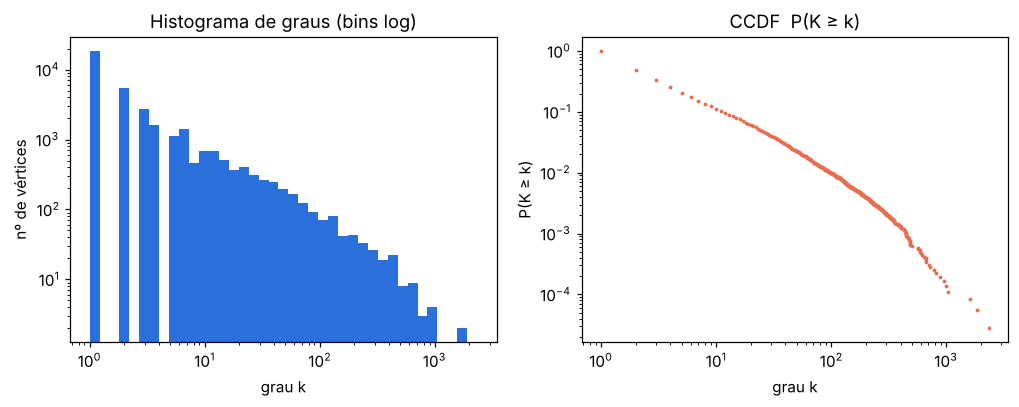

In [10]:
ks, pk = M.distribuicao_graus(adj)
kc, pc = M.ccdf(adj)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist([len(v) for v in adj.values()], bins=np.logspace(0, np.log10(rg["grau_max"]), 40), color="#2a6fdb")
ax[0].set(xscale="log", yscale="log", title="Histograma de graus (bins log)", xlabel="grau k", ylabel="nº de vértices")
ax[1].loglog(kc, pc, ".", ms=3, color="#e76f51")
ax[1].set(title="CCDF  P(K ≥ k)", xlabel="grau k", ylabel="P(K ≥ k)")
fig.savefig(FIG / "03_distribuicao_graus.png"); plt.show()

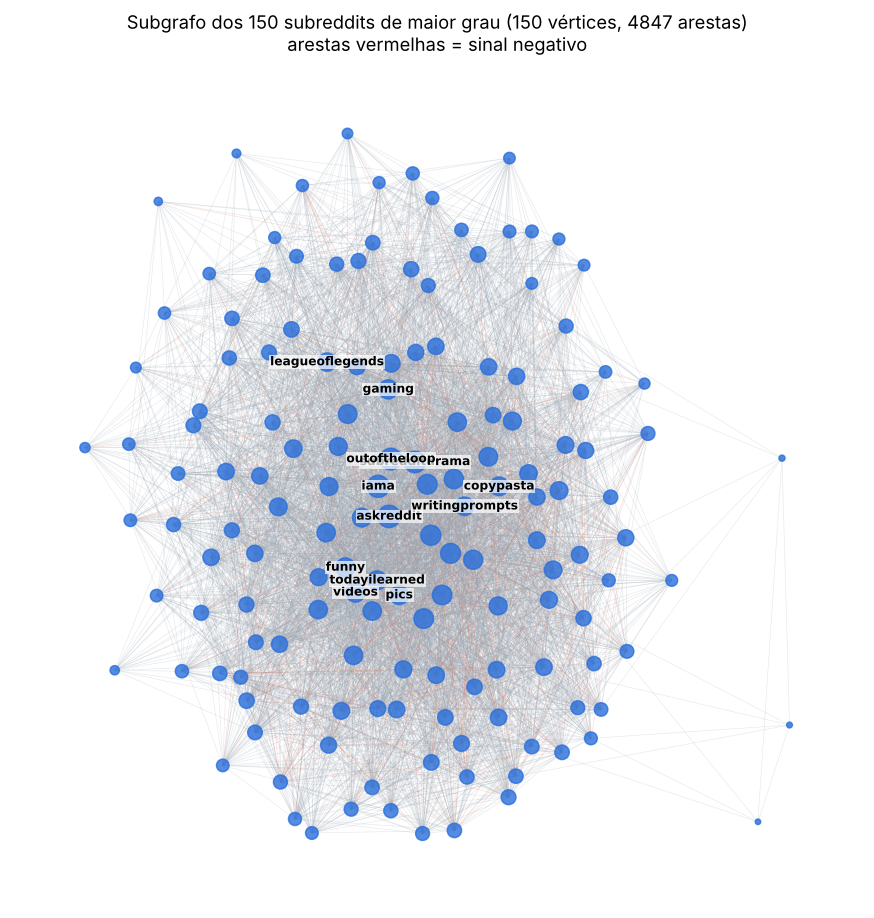

In [11]:
top = sorted(G_und.degree, key=lambda x: -x[1])[:150]
H = G_und.subgraph([u for u, _ in top])
H = H.subgraph(max(nx.connected_components(H), key=len))
pos = nx.kamada_kawai_layout(H, weight=None)
deg = dict(H.degree)
cores = ["#e76f51" if d["sign"] < 0 else "#9aa5b1" for *_, d in H.edges(data=True)]
fig, ax = plt.subplots(figsize=(10, 10))
nx.draw_networkx_edges(H, pos, edge_color=cores, alpha=0.25, width=0.4, ax=ax)
nx.draw_networkx_nodes(H, pos, node_size=[5 + deg[u] * 1.5 for u in H], node_color="#2a6fdb", alpha=0.8, ax=ax)
lab = {u: u for u in sorted(H, key=lambda u: -G_und.degree[u])[:12]}
nx.draw_networkx_labels(H, pos, lab, font_size=8, font_weight="bold", bbox=dict(fc="white", ec="none", alpha=0.7, pad=0.5), ax=ax)
ax.set_title(f"Subgrafo dos 150 subreddits de maior grau ({H.number_of_nodes()} vértices, {H.number_of_edges()} arestas)\narestas vermelhas = sinal negativo")
ax.axis("off"); fig.savefig(FIG / "03b_visualizacao.png"); plt.show()

## 4. Parte II – Algoritmos da disciplina

### 4.1 Validação das implementações próprias (comparação com networkx)

In [12]:
S = T.subgrafo_bfs(G_lcc, 1500, seed=SEED)
aS, awS, eS = A.lista_adj(S), A.lista_adj_ponderada(S), A.lista_arestas(S)
s0 = next(iter(S))
ref = nx.single_source_dijkstra_path_length(S, s0)
assert A.bfs(aS, s0) == nx.single_source_shortest_path_length(S, s0)
assert set(A.dfs(aS, s0)) == set(S)
assert all(abs(A.dijkstra(awS, s0)[k] - ref[k]) < 1e-9 for k in ref)
bf, neg, _ = A.bellman_ford(list(S), eS, s0, dirigido=False)
assert not neg and all(abs(bf[k] - ref[k]) < 1e-9 for k in ref)
nosS, D = A.floyd_warshall(S); i0 = nosS.index(s0)
assert all(abs(D[i0, nosS.index(k)] - ref[k]) < 1e-9 for k in ref)
mst_ref = sum(d["weight"] for *_, d in nx.minimum_spanning_edges(S, data=True))
assert abs(A.kruskal(list(S), eS)[1] - mst_ref) < 1e-9 and abs(A.prim(awS)[1] - mst_ref) < 1e-9
succ = {u: list(G_dir.successors(u)) for u in G_dir}
pred = {u: list(G_dir.predecessors(u)) for u in G_dir}
scc = A.tarjan_scc(succ)
assert sorted(map(len, scc)) == sorted(map(len, nx.strongly_connected_components(G_dir)))
print("Todas as implementações conferem com o networkx.")

Todas as implementações conferem com o networkx.


### 4.2 Resultados dos algoritmos no grafo

In [13]:
s_hub = max(G_lcc.degree, key=lambda x: x[1])[0]
awL, eL = A.lista_adj_ponderada(G_lcc), A.lista_arestas(G_lcc)
d_bfs = A.bfs(adj_lcc, s_hub)
ordem_dfs = A.dfs(adj_lcc, s_hub)
eul_u = A.euleriano_nao_dirigido(adj)
eul_d = A.euleriano_dirigido(succ, pred)
d_dij = A.dijkstra(awL, s_hub)
d_bf, neg_bf, it_bf = A.bellman_ford(list(G_lcc), eL, s_hub, dirigido=False)
agm_k, peso_k = A.kruskal(list(G_lcc), eL)
agm_p, peso_p = A.prim(awL)
wcc = list(nx.weakly_connected_components(G_dir))

res_alg = pd.DataFrame([
    ["BFS", f"origem = {s_hub}; alcança {len(d_bfs)} vértices; excentricidade = {max(d_bfs.values())}"],
    ["DFS", f"origem = {s_hub}; visita {len(ordem_dfs)} vértices"],
    ["Euler (não dirigido)", f"{eul_u['vertices_grau_impar']} vértices de grau ímpar; conexo={eul_u['conexo']} → euleriano={eul_u['euleriano']}, semi={eul_u['semi_euleriano']}"],
    ["Euler (dirigido)", f"{eul_d['vertices_desbalanceados']} vértices com entrada≠saída; fracamente conexo={eul_d['fracamente_conexo']} → euleriano={eul_d['euleriano']}"],
    ["Dijkstra", f"w = 1/count; distância máxima a partir de {s_hub} = {max(d_dij.values()):.3f}"],
    ["Bellman-Ford", f"mesmas distâncias que Dijkstra: {all(abs(d_bf[k]-d_dij[k])<1e-9 for k in d_dij)}; convergiu em {it_bf} iterações; ciclo negativo = {neg_bf}"],
    ["Floyd-Warshall", "executado só em subgrafos (n ≤ 2000): O(n³) e matriz n×n de 34.671² ≈ 1,2·10⁹ células (~9,6 GB) inviáveis"],
    ["Tarjan (SCC)", f"{len(scc)} componentes fortemente conexas; maior = {len(scc[0])} vértices ({len(scc[0])/G_dir.number_of_nodes():.1%}); {sum(len(c)==1 for c in scc)} SCCs unitárias; {len(wcc)} componentes fracamente conexas"],
    ["Kruskal", f"{len(agm_k)} arestas; peso total = {peso_k:.4f}"],
    ["Prim", f"{len(agm_p)} arestas; peso total = {peso_p:.4f} (igual ao Kruskal: {abs(peso_k-peso_p)<1e-6})"],
], columns=["Algoritmo", "Resultado"]).set_index("Algoritmo")
salvar_tabela(res_alg, "04_resultados_algoritmos")

,Resultado
Algoritmo,
BFS,origem = askreddit; alcança 34671 vértices; ex...
DFS,origem = askreddit; visita 34671 vértices
Euler (não dirigido),25306 vértices de grau ímpar; conexo=False → e...
Euler (dirigido),32257 vértices com entrada≠saída; fracamente c...
Dijkstra,w = 1/count; distância máxima a partir de askr...
Bellman-Ford,mesmas distâncias que Dijkstra: True; convergi...
Floyd-Warshall,executado só em subgrafos (n ≤ 2000): O(n³) e ...
Tarjan (SCC),24071 componentes fortemente conexas; maior = ...
Kruskal,34670 arestas; peso total = 25435.5313


**Bellman-Ford com pesos com sinal (experimento):** usando o sinal como peso (−1 para links negativos) no grafo **dirigido**, o algoritmo detecta ciclos negativos – ciclos de "hostilidade" líquida entre comunidades. Como o problema com ciclos negativos não tem solução de caminho mínimo, este é o caso em que Bellman-Ford é aplicável e Dijkstra não.

In [14]:
Sd = G_dir.subgraph(T.subgrafo_bfs(G_lcc, 2000, raiz=s_hub, seed=SEED)).copy()
arest_sinal = [(u, v, float(d["sign"])) for u, v, d in Sd.edges(data=True)]
_, neg_sinal, it_sinal = A.bellman_ford(list(Sd), arest_sinal, s_hub, dirigido=True)
print(f"Subgrafo dirigido com {Sd.number_of_nodes()} vértices e {Sd.number_of_edges()} arestas "
      f"({sum(w < 0 for *_, w in arest_sinal)} negativas): ciclo negativo = {neg_sinal} (iterações: {it_sinal})")

Subgrafo dirigido com 2000 vértices e 28460 arestas (2333 negativas): ciclo negativo = True (iterações: 1999)


### 4.3 Tempo de execução (30 repetições → média, desvio padrão, IC 95%)
Com $n = 30 \geq 30$ usamos a Normal: $\bar{x} \pm z_{\alpha/2}\,\sigma/\sqrt{n}$, $z_{0.025} = 1.96$.
Fontes sorteadas a cada repetição quando o algoritmo tem vértice de origem.

In [15]:
rng = random.Random(SEED)
fontes = rng.sample(list(G_lcc), 30)
subs_fw = {n: T.subgrafo_bfs(G_lcc, n, seed=SEED + n) for n in (100, 250, 500, 1000)}
n_, m_ = G_lcc.number_of_nodes(), G_lcc.number_of_edges()
casos = [
    ("BFS", "O(n + m)", "maior componente", lambda s: A.bfs(adj_lcc, s), [(s,) for s in fontes]),
    ("DFS", "O(n + m)", "maior componente", lambda s: A.dfs(adj_lcc, s), [(s,) for s in fontes]),
    ("Euler (não dirigido)", "O(n + m)", "G_und", lambda: A.euleriano_nao_dirigido(adj), [()]),
    ("Euler (dirigido)", "O(n + m)", "G_dir", lambda: A.euleriano_dirigido(succ, pred), [()]),
    ("Dijkstra", "O((n + m) log n)", "maior componente", lambda s: A.dijkstra(awL, s), [(s,) for s in fontes]),
    ("Bellman-Ford", "O(n · m)", "maior componente", lambda s: A.bellman_ford(list(G_lcc), eL, s, dirigido=False), [(s,) for s in fontes]),
    ("Tarjan (SCC)", "O(n + m)", "G_dir", lambda: A.tarjan_scc(succ), [()]),
    ("Kruskal", "O(m log m)", "maior componente", lambda: A.kruskal(list(G_lcc), eL), [()]),
    ("Prim", "O(m log n)", "maior componente", lambda: A.prim(awL), [()]),
] + [(f"Floyd-Warshall (n={n})", "O(n³)", f"subgrafo n={n}", (lambda G: lambda: A.floyd_warshall(G))(S_), [()])
     for n, S_ in subs_fw.items()]

linhas = []
for nome, cx, grafo, f, ent in casos:
    r = M.medir(f, ent, reps=30)
    linhas.append({"Algoritmo": nome, "Complexidade": cx, "Grafo": grafo, **r})
    print(f"{nome:28s} {r['media_s']*1e3:10.2f} ms ± {r['desvio_s']*1e3:.2f}")
tempos = pd.DataFrame(linhas).set_index("Algoritmo")
salvar_tabela(tempos, "04_tempos_execucao")

BFS                               28.51 ms ± 2.03


DFS                               32.86 ms ± 44.85


Euler (não dirigido)              40.52 ms ± 3.60


Euler (dirigido)                 151.90 ms ± 92.04


Dijkstra                         124.12 ms ± 4.82


Bellman-Ford                     394.45 ms ± 50.73


... (3 outputs left out)

Floyd-Warshall (n=250)            17.07 ms ± 1.33


Floyd-Warshall (n=500)           216.98 ms ± 12.41


Floyd-Warshall (n=1000)         1840.62 ms ± 113.86


,Complexidade,Grafo,n,media_s,desvio_s,ic_inf_s,ic_sup_s,distribuicao
Algoritmo,,,,,,,,
BFS,O(n + m),maior componente,30,0.028507,0.002034,0.027779,0.029234,Normal (z)
DFS,O(n + m),maior componente,30,0.032864,0.044854,0.016813,0.048914,Normal (z)
Euler (não dirigido),O(n + m),G_und,30,0.040520,0.003596,0.039233,0.041806,Normal (z)
Euler (dirigido),O(n + m),G_dir,30,0.151896,0.092040,0.118961,0.184832,Normal (z)
Dijkstra,O((n + m) log n),maior componente,30,0.124124,0.004819,0.122399,0.125848,Normal (z)
Bellman-Ford,O(n · m),maior componente,30,0.394446,0.050734,0.376292,0.412601,Normal (z)
Tarjan (SCC),O(n + m),G_dir,30,0.074408,0.048322,0.057116,0.091699,Normal (z)
Kruskal,O(m log m),maior componente,30,0.096207,0.003934,0.094799,0.097614,Normal (z)
Prim,O(m log n),maior componente,30,0.239582,0.017536,0.233307,0.245857,Normal (z)


### 4.4 Complexidade observada × teórica (subgrafos de tamanho crescente, 5 repetições)

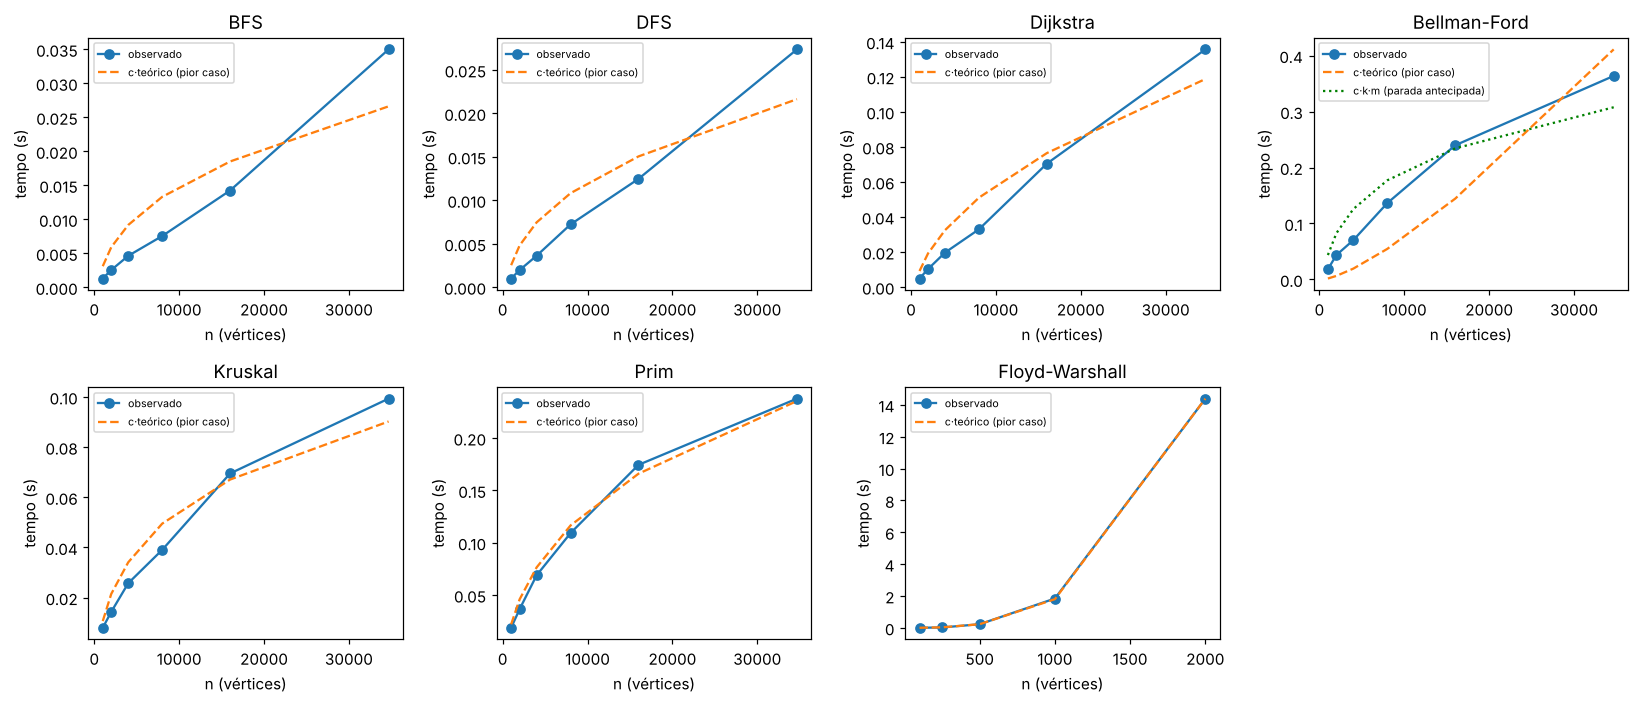

In [16]:
tamanhos = [1000, 2000, 4000, 8000, 16000, n_]
algs_esc = {
    "BFS": (lambda G, a, aw, e, s: A.bfs(a, s), lambda n, m: n + m),
    "DFS": (lambda G, a, aw, e, s: A.dfs(a, s), lambda n, m: n + m),
    "Dijkstra": (lambda G, a, aw, e, s: A.dijkstra(aw, s), lambda n, m: (n + m) * math.log2(n)),
    "Bellman-Ford": (lambda G, a, aw, e, s: A.bellman_ford(list(G), e, s, dirigido=False), lambda n, m: n * m),
    "Kruskal": (lambda G, a, aw, e, s: A.kruskal(list(G), e), lambda n, m: m * math.log2(m)),
    "Prim": (lambda G, a, aw, e, s: A.prim(aw), lambda n, m: m * math.log2(n)),
}
esc = []
for n in tamanhos:
    G_ = G_lcc if n == n_ else T.subgrafo_bfs(G_lcc, n, seed=SEED)
    a_, aw_, e_ = A.lista_adj(G_), A.lista_adj_ponderada(G_), A.lista_arestas(G_)
    fs = random.Random(n).sample(list(G_), 5)
    for nome, (f, _) in algs_esc.items():
        r = M.medir(lambda s: f(G_, a_, aw_, e_, s), [(s,) for s in fs], reps=5)
        esc.append({"alg": nome, "n": G_.number_of_nodes(), "m": G_.number_of_edges(), "t": r["media_s"]})
for n in (100, 250, 500, 1000, 2000):
    G_ = subs_fw.get(n) or T.subgrafo_bfs(G_lcc, n, seed=SEED + n)
    r = M.medir(lambda: A.floyd_warshall(G_), [()], reps=5)
    esc.append({"alg": "Floyd-Warshall", "n": n, "m": G_.number_of_edges(), "t": r["media_s"]})
esc = pd.DataFrame(esc)
esc.to_csv(RES / "04_escalabilidade.csv", index=False)

teor = {**{k: v[1] for k, v in algs_esc.items()}, "Floyd-Warshall": lambda n, m: n ** 3}
fig, axs = plt.subplots(2, 4, figsize=(15, 6.5)); axs = axs.ravel()
for ax, (nome, d) in zip(axs, esc.groupby("alg", sort=False)):
    x = np.array([teor[nome](float(n), float(m)) for n, m in zip(d.n, d.m)], dtype=float)
    c = (d.t.values @ x) / (x @ x)                         # ajuste t ≈ c·f(n,m)
    ax.plot(d.n, d.t, "o-", label="observado")
    ax.plot(d.n, c * x, "--", label="c·teórico (pior caso)")
    if nome == "Bellman-Ford":                             # parada antecipada: O(k·m), k pequeno
        x2 = d.m.values.astype(float); c2 = (d.t.values @ x2) / (x2 @ x2)
        ax.plot(d.n, c2 * x2, ":", color="green", label="c·k·m (parada antecipada)")
    ax.set(title=nome, xlabel="n (vértices)", ylabel="tempo (s)"); ax.legend(fontsize=7)
axs[-1].axis("off")
fig.tight_layout(); fig.savefig(FIG / "04_complexidade_observada.png"); plt.show()

**Leitura do gráfico.** BFS, DFS, Dijkstra, Kruskal e Prim acompanham a curva teórica, e o Floyd-Warshall segue o crescimento cúbico. No Bellman-Ford, a implementação para quando uma rodada não altera nenhuma distância: no grafo real isso ocorre após poucas rodadas (6–8, ver tabela 04), em vez das n − 1 do pior caso. O custo efetivo é O(k·m), com k pequeno — muito abaixo de O(n·m) em número de operações. Com só seis tamanhos e a constante ajustada livremente, as curvas c·n·m e c·k·m ficam próximas no gráfico, então o número de rodadas é a evidência mais direta.

## 5. Parte III – (1) Small-world (Apêndice A)

Critério do enunciado: $L(G) \approx L_{aleatório}$ e $C(G) \gg C_{aleatório}$.
O grafo aleatório equivalente é $G(n, m)$ (Erdős–Rényi, gerador próprio) com o mesmo $n$ e $m$ da maior componente – logo o mesmo grau médio. Média de 5 grafos aleatórios; $L$ estimado com 300 BFS por grafo (código próprio, sem bibliotecas prontas). Também mostramos as aproximações teóricas $C_{al} \approx \bar k/n$ e $L_{al} \approx \ln n / \ln \bar k$, e o índice $\sigma = (C/C_{al})/(L/L_{al})$ como complemento.

In [17]:
sw = M.small_world(adj_lcc, reps=5, fontes=300, seed=SEED)
sw_tab = pd.Series(sw, name="valor").to_frame()
salvar_tabela(sw_tab, "05_small_world")

,valor
n,34671.000000
m,123570.000000
grau_medio,7.128147
C(G),0.186170
C_aleatorio,0.000215
C_aleatorio_teorico,0.000206
C(G)/C_aleatorio,864.634343
L(G),3.917032
L_aleatorio,5.550879
L_aleatorio_teorico,5.322498


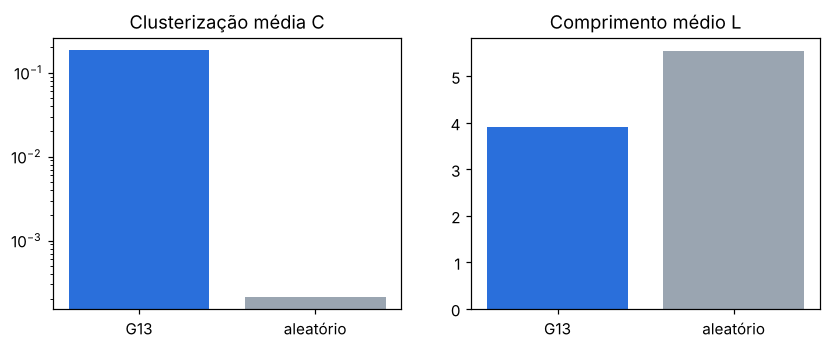

C(G)/C_al = 864.6   L(G)/L_al = 0.71   sigma = 1225.3


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].bar(["G13", "aleatório"], [sw["C(G)"], sw["C_aleatorio"]], color=["#2a6fdb", "#9aa5b1"]); ax[0].set(title="Clusterização média C", yscale="log")
ax[1].bar(["G13", "aleatório"], [sw["L(G)"], sw["L_aleatorio"]], color=["#2a6fdb", "#9aa5b1"]); ax[1].set(title="Comprimento médio L")
fig.savefig(FIG / "05_small_world.png"); plt.show()
print(f"C(G)/C_al = {sw['C(G)/C_aleatorio']:.1f}   L(G)/L_al = {sw['L(G)/L_aleatorio']:.2f}   sigma = {sw['sigma']:.1f}")

## 6. Parte III – (2) Lei de potência (Apêndice B)

Modelo: $P(k) \sim C\,k^{-\gamma}$ com $\gamma > 1$. Em escala log-log, $\log P(k) = -\gamma \log k + \log C$ é uma reta.
Estimamos $\gamma$ (i) por regressão linear em $\log P(k)$ vs $\log k$ (método do enunciado) – com $P(k)$ bruto e com histograma de bins logarítmicos, que reduz o ruído da cauda –, (ii) pela CCDF ($P(K\ge k) \sim k^{-(\gamma-1)}$) e (iii) por máxima verossimilhança (Clauset et al., 2009) como verificação.

In [19]:
pl = M.lei_potencia(adj)
pl_tab = pd.Series(pl, name="valor").to_frame()
salvar_tabela(pl_tab, "06_lei_potencia")

,valor
gamma_pk,1.438929
r2_pk,0.860864
logC_pk,-0.912166
gamma_pk_bins_log,2.112928
r2_pk_bins_log,0.991795
logC_pk_bins_log,0.160939
gamma_ccdf,2.324445
r2_ccdf,0.962046
gamma_mle,2.216206
kmin_mle,31.000000


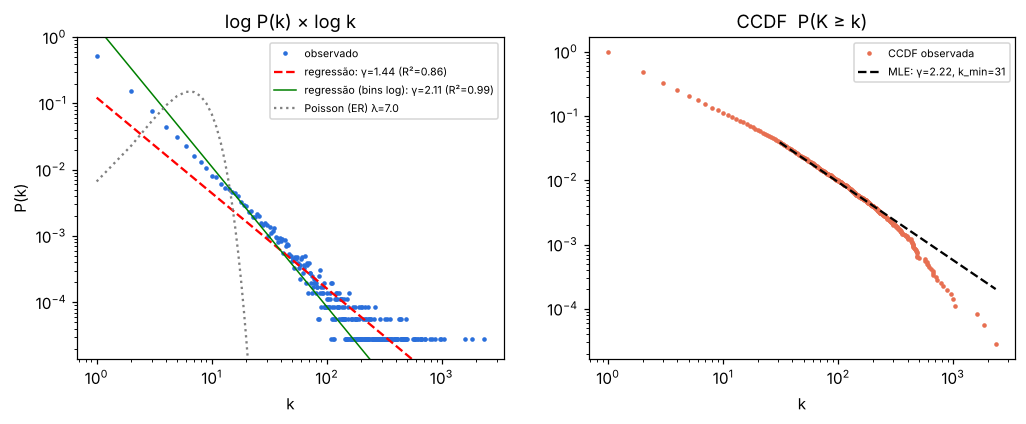

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].loglog(ks, pk, ".", ms=4, color="#2a6fdb", label="observado")
xx = np.array([ks.min(), ks.max()], float)
ax[0].loglog(xx, 10 ** pl["logC_pk"] * xx ** (-pl["gamma_pk"]), "r--", label=f"regressão: γ={pl['gamma_pk']:.2f} (R²={pl['r2_pk']:.2f})")
ax[0].loglog(xx, 10 ** pl["logC_pk_bins_log"] * xx ** (-pl["gamma_pk_bins_log"]), "g-", lw=1, label=f"regressão (bins log): γ={pl['gamma_pk_bins_log']:.2f} (R²={pl['r2_pk_bins_log']:.2f})")
lam = rg["grau_medio"]; kk = np.arange(1, 60)
from scipy.stats import poisson
ax[0].loglog(kk, poisson.pmf(kk, lam), ":", color="gray", label=f"Poisson (ER) λ={lam:.1f}")
ax[0].set(title="log P(k) × log k", xlabel="k", ylabel="P(k)", ylim=(pk.min() / 2, 1)); ax[0].legend(fontsize=7)
ax[1].loglog(kc, pc, ".", ms=4, color="#e76f51", label="CCDF observada")
km = pl["kmin_mle"]; xs = np.array([km, kc.max()], float)
p_km = pc[np.searchsorted(kc, km)]
ax[1].loglog(xs, p_km * (xs / km) ** (1 - pl["gamma_mle"]), "k--", label=f"MLE: γ={pl['gamma_mle']:.2f}, k_min={km}")
ax[1].set(title="CCDF  P(K ≥ k)", xlabel="k"); ax[1].legend(fontsize=7)
fig.savefig(FIG / "06_lei_potencia.png"); plt.show()

## 7. Parte III – (3) Robustez (Apêndice C)

Política: maior componente conexa. $n = |V|$, $r = \lceil 0.05 \times n \rceil$.
Métricas: **A** tamanho relativo da maior componente ($S$, relativo ao $n$ original); **B** nº de componentes ($c$); **C** comprimento médio dos caminhos na maior componente (200 BFS); **D** fração de vértices isolados.
Aleatória: 30 repetições. Ataque: ranking fixo por **grau** e por **betweenness** (exata, igraph).

In [21]:
orig = R.metricas(adj_lcc, n_, fontes=200, seed=SEED)
aleat = pd.DataFrame(R.remocao_aleatoria(adj_lcc, reps=30, seed=SEED))
grau_c = dict(G_lcc.degree)
t0 = time.perf_counter()
btw = dict(zip(g_lcc.vs["_nx_name"], g_lcc.betweenness(directed=False)))
print(f"betweenness: {time.perf_counter() - t0:.0f} s")
at_grau = R.ataque_direcionado(adj_lcc, grau_c, seed=SEED)
at_btw = R.ataque_direcionado(adj_lcc, btw, seed=SEED)
rob = pd.DataFrame({
    "original": orig,
    "aleatória (média)": aleat.mean(), "aleatória (desvio)": aleat.std(),
    "ataque grau": at_grau, "ataque betweenness": at_btw,
}).T
rob.insert(0, "r removidos", [0, R.r_remover(n_), R.r_remover(n_), R.r_remover(n_), R.r_remover(n_)])
salvar_tabela(rob, "07_robustez")

betweenness: 115 s


,r removidos,A_S,B_c,C_L,D_isolados
original,0,1.000000,1.000000,3.920676,0.000000
aleatória (média),1734,0.923654,869.200000,3.910185,0.025371
aleatória (desvio),1734,0.004567,154.936338,0.041507,0.004617
ataque grau,1734,0.366156,17458.000000,12.231163,0.485867
ataque betweenness,1734,0.343284,18339.000000,8.978280,0.511249


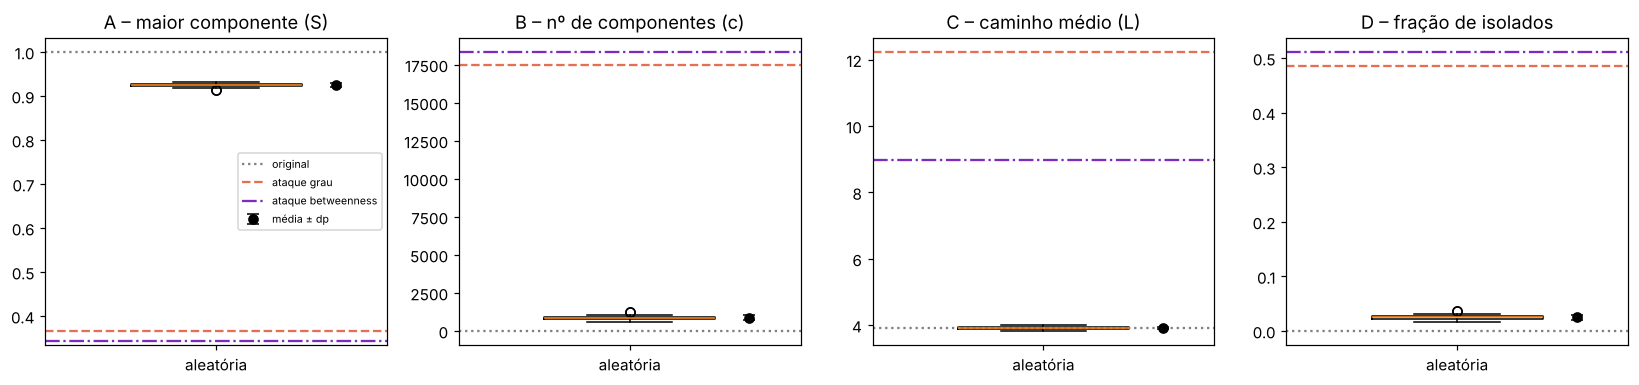

S_rand = 0.924  S_cent(grau) = 0.366  S_cent(btw) = 0.343
c_rand = 869.2  c_cent(grau) = 17458  c_cent(btw) = 18339


In [22]:
nomes = {"A_S": "A – maior componente (S)", "B_c": "B – nº de componentes (c)", "C_L": "C – caminho médio (L)", "D_isolados": "D – fração de isolados"}
fig, axs = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, (k, t) in zip(axs, nomes.items()):
    ax.boxplot(aleat[k], widths=0.5)
    mu, sd = aleat[k].mean(), aleat[k].std()
    ax.errorbar([1.35], [mu], yerr=[sd], fmt="o", color="k", capsize=4, label="média ± dp")
    ax.axhline(orig[k], color="gray", ls=":", label="original")
    ax.axhline(at_grau[k], color="#e76f51", ls="--", label="ataque grau")
    ax.axhline(at_btw[k], color="#7b2cbf", ls="-.", label="ataque betweenness")
    ax.set(title=t, xticks=[1], xticklabels=["aleatória"])
axs[0].legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "07_robustez.png"); plt.show()
S_r, S_c = aleat["A_S"].mean(), at_grau["A_S"]
c_r, c_c = aleat["B_c"].mean(), at_grau["B_c"]
print(f"S_rand = {S_r:.3f}  S_cent(grau) = {S_c:.3f}  S_cent(btw) = {at_btw['A_S']:.3f}")
print(f"c_rand = {c_r:.1f}  c_cent(grau) = {c_c}  c_cent(btw) = {at_btw['B_c']}")

## 8. Parte III – (4) Descobertas

In [23]:
pr = nx.pagerank(G_dir, weight="count")
ind, outd = dict(G_dir.in_degree), dict(G_dir.out_degree)
top10 = lambda d: [f"{k} ({v:.4g})" for k, v in sorted(d.items(), key=lambda x: -x[1])[:10]]
hubs = pd.DataFrame({"grau de entrada": top10(ind), "grau de saída": top10(outd),
                     "PageRank": top10(pr), "betweenness": top10(btw)}, index=range(1, 11))
salvar_tabela(hubs, "08_hubs")

,grau de entrada,grau de saída,PageRank,betweenness
1,askreddit (2161),subredditdrama (1350),askreddit (0.01664),askreddit (7.298e+07)
2,iama (1646),copypasta (636),iama (0.01342),iama (5.341e+07)
3,pics (953),drama (600),videos (0.008163),subredditdrama (4.483e+07)
4,videos (879),subredditoftheday (559),pics (0.006779),writingprompts (2.526e+07)
5,todayilearned (816),outoftheloop (507),leagueoflegends (0.005295),outoftheloop (2.234e+07)
6,funny (757),circlejerkcopypasta (472),todayilearned (0.004728),videos (1.74e+07)
7,writingprompts (717),tipofmypenis (472),mhoc (0.004366),leagueoflegends (1.631e+07)
8,worldnews (661),shitliberalssay (470),worldnews (0.004024),gaming (1.53e+07)
9,mhoc (595),justunsubbed (464),writingprompts (0.004),pics (1.426e+07)
10,outoftheloop (592),conspiracy (433),funny (0.003963),tipofmypenis (1.398e+07)


In [24]:
neg = df[df.sign == -1]
negativos = pd.DataFrame({
    "mais links negativos enviados": [f"{k} ({v})" for k, v in neg.src.value_counts().head(10).items()],
    "mais links negativos recebidos": [f"{k} ({v})" for k, v in neg.dst.value_counts().head(10).items()],
}, index=range(1, 11))
salvar_tabela(negativos, "08_links_negativos")
reciproc = nx.reciprocity(G_dir)
frac_neg_por_src = neg.src.value_counts() / df.src.value_counts()
conc = neg.src.value_counts().head(int(0.01 * neg.src.nunique())).sum() / len(neg)
print(f"Reciprocidade (arestas dirigidas com volta): {reciproc:.3f}")
print(f"Maior SCC: {len(scc[0])} vértices ({len(scc[0]) / G_dir.number_of_nodes():.1%}) × maior WCC: {len(max(wcc, key=len))}")
print(f"1% dos subreddits que mais enviam links negativos respondem por {conc:.1%} desses links")

Reciprocidade (arestas dirigidas com volta): 0.196
Maior SCC: 11564 vértices (32.3%) × maior WCC: 34671
1% dos subreddits que mais enviam links negativos respondem por 39.0% desses links


*(A interpretação da descoberta mais interessante fica no relatório; os números acima e as tabelas 08 dão a base.)*

## 9. EXTRA – Comparação com modelos clássicos

In [25]:
n0, m0 = n_, m_
kbar = 2 * m0 / n0
modelos = {
    "G13 (maior componente)": G_lcc,
    "Erdős–Rényi G(n,m)": nx.gnm_random_graph(n0, m0, seed=1),
    "Barabási–Albert": nx.barabasi_albert_graph(n0, max(1, round(kbar / 2)), seed=1),
    "Watts–Strogatz (p=0.1)": nx.watts_strogatz_graph(n0, 2 * max(1, round(kbar / 2)), 0.1, seed=1),
}
lin = []
for nome, Gm in modelos.items():
    am = A.lista_adj(Gm)
    amc = M.maior_componente_adj(am)
    c_, _, _ = M.clusterizacao(am)
    L_, _, _ = M.caminho_medio_amostrado(amc, 200, 1)
    pl_ = M.lei_potencia(am)
    lin.append({"modelo": nome, "n": len(am), "m": sum(map(len, am.values())) // 2,
                "grau máx": max(map(len, am.values())), "C médio": c_, "L": L_,
                "γ (regressão bins log)": pl_["gamma_pk_bins_log"], "γ (MLE)": pl_["gamma_mle"]})
salvar_tabela(pd.DataFrame(lin).set_index("modelo"), "09_modelos_classicos")

,n,m,grau máx,C médio,L,γ (regressão bins log),γ (MLE)
modelo,,,,,,,
G13 (maior componente),34671,123570,2336,0.186170,3.855501,2.109955,2.216206
"Erdős–Rényi G(n,m)",34671,123570,22,0.000165,5.522228,1.459052,2.918330
Barabási–Albert,34671,138668,550,0.002405,4.253217,2.891376,2.874214
Watts–Strogatz (p=0.1),34671,138684,12,0.473073,8.069887,-5.028470,5.708763


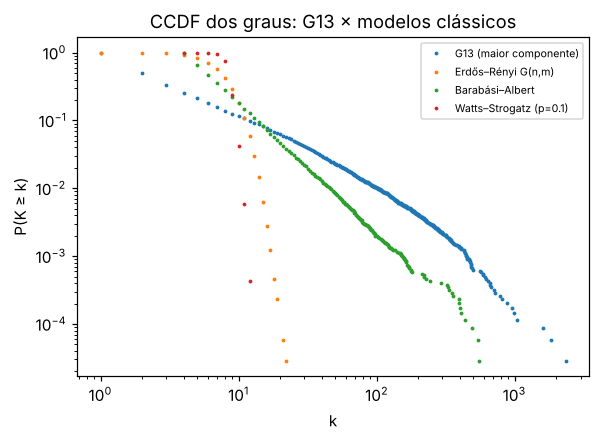

In [26]:
fig, ax = plt.subplots(figsize=(6, 4))
for nome, Gm in modelos.items():
    k_, p_ = M.ccdf(A.lista_adj(Gm)); ax.loglog(k_, p_, ".", ms=3, label=nome)
ax.set(title="CCDF dos graus: G13 × modelos clássicos", xlabel="k", ylabel="P(K ≥ k)"); ax.legend(fontsize=7)
fig.savefig(FIG / "09_modelos_ccdf.png"); plt.show()

## 10. Arquivos gerados

In [27]:
print("Figuras:", sorted(p.name for p in FIG.glob("*.png")))
print("Tabelas:", sorted(p.name for p in RES.glob("*.csv")))
print("Dados tratados:", sorted(p.name for p in PROC.iterdir()))

Figuras: ['01_original_tempo_sinal.png', '03_distribuicao_graus.png', '03b_visualizacao.png', '04_complexidade_observada.png', '05_small_world.png', '06_lei_potencia.png', '07_robustez.png', '09_modelos_ccdf.png']
Tabelas: ['01_dados_originais.csv', '02_tratamentos.csv', '03_parte1_medidas.csv', '03_tamanho_componentes.csv', '04_escalabilidade.csv', '04_resultados_algoritmos.csv', '04_tempos_execucao.csv', '05_small_world.csv', '06_lei_potencia.csv', '07_robustez.csv', '08_hubs.csv', '08_links_negativos.csv', '09_modelos_classicos.csv']
Dados tratados: ['arestas_dirigidas.csv', 'arestas_nao_dirigidas.csv', 'maior_componente.edgelist.gz']
